In [1]:
%pip install -q "mediapipe>=0.10.21,<0.11" kagglehub

from importlib.metadata import PackageNotFoundError, version

for package in ("mediapipe", "kagglehub", "scikit-learn", "joblib"):
    print(f"{package}: {version(package)}")

for package in (
    "opencv-python",
    "opencv-python-headless",
    "opencv-contrib-python",
    "opencv-contrib-python-headless",
):
    try:
        installed_version = version(package)
    except PackageNotFoundError:
        continue
    print(f"{package}: {installed_version}")
    break
else:
    raise RuntimeError("No OpenCV package was found in this runtime.")

mediapipe: 0.10.35
kagglehub: 1.0.3
scikit-learn: 1.6.1
joblib: 1.6.0
opencv-python: 5.0.0.93


In [2]:
from pathlib import Path

import kagglehub

DATASET_HANDLE = "grassknoted/asl-alphabet"
CLASSES = ("A", "B", "C", "L", "Y")
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}

dataset_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))

# The archive may contain nested folders named asl_alphabet_train.
candidates = [dataset_dir, *dataset_dir.rglob("asl_alphabet_train")]
train_dir = next(
    (
        folder
        for folder in candidates
        if all((folder / label).is_dir() for label in CLASSES)
    ),
    None,
)

if train_dir is None:
    raise FileNotFoundError(
        f"Could not find a training folder containing {CLASSES} under {dataset_dir}"
    )

image_paths = {}
print(f"Training folder: {train_dir}")

for label in CLASSES:
    paths = sorted(
        path
        for path in (train_dir / label).iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    if not paths:
        raise FileNotFoundError(f"No images found in {train_dir / label}")

    image_paths[label] = paths
    print(f"{label}: {len(paths):,} images")

print(f"Total selected: {sum(map(len, image_paths.values())):,} images")

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Training folder: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
A: 3,000 images
B: 3,000 images
C: 3,000 images
L: 3,000 images
Y: 3,000 images
Total selected: 15,000 images


In [3]:
from urllib.request import urlretrieve

import cv2
import mediapipe as mp
import numpy as np
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm.auto import tqdm

SEED = 42
IMAGES_PER_CLASS = 800

HAND_MODEL_PATH = Path("/content/hand_landmarker.task")
HAND_MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
    "hand_landmarker/float16/1/hand_landmarker.task"
)

if not HAND_MODEL_PATH.is_file():
    temp_path = HAND_MODEL_PATH.with_suffix(".download")
    urlretrieve(HAND_MODEL_URL, str(temp_path))
    temp_path.replace(HAND_MODEL_PATH)

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=str(HAND_MODEL_PATH),
        delegate=python.BaseOptions.Delegate.CPU,
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
)


def normalize_landmarks(landmarks, width, height):
    # MediaPipe expresses x and z relative to image width, and y to height.
    points = np.array(
        [(lm.x, lm.y * height / width, lm.z) for lm in landmarks],
        dtype=np.float32,
    )
    points -= points[0].copy()  # Landmark 0 is the wrist.
    scale = np.linalg.norm(points, axis=1).max()

    if not np.isfinite(scale) or scale <= 1e-6:
        return None

    return (points / scale).reshape(63)


rng = np.random.default_rng(SEED)
features = []
labels = []
feature_paths = []

with vision.HandLandmarker.create_from_options(options) as detector:
    for label in CLASSES:
        paths = image_paths[label]
        sample_size = min(IMAGES_PER_CLASS, len(paths))
        indices = rng.choice(len(paths), size=sample_size, replace=False)

        usable = 0
        unreadable = 0

        for index in tqdm(indices, desc=f"Letter {label}", unit="image"):
            path = paths[index]
            bgr = cv2.imread(str(path))
            if bgr is None:
                unreadable += 1
                continue

            height, width = bgr.shape[:2]
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))

            if not result.hand_landmarks:
                continue

            vector = normalize_landmarks(result.hand_landmarks[0], width, height)
            if vector is None:
                continue

            features.append(vector)
            labels.append(label)
            feature_paths.append(path)
            usable += 1

        print(
            f"{label}: {usable}/{sample_size} usable "
            f"({usable / sample_size:.1%}), {unreadable} unreadable"
        )

X = np.asarray(features, dtype=np.float32).reshape(-1, 63)
y = np.asarray(labels, dtype=str)

print(f"\nFeature matrix: {X.shape}")
print(f"Labels: {y.shape}")

Letter A:   0%|          | 0/800 [00:00<?, ?image/s]

A: 592/800 usable (74.0%), 0 unreadable


Letter B:   0%|          | 0/800 [00:00<?, ?image/s]

B: 594/800 usable (74.2%), 0 unreadable


Letter C:   0%|          | 0/800 [00:00<?, ?image/s]

C: 538/800 usable (67.2%), 0 unreadable


Letter L:   0%|          | 0/800 [00:00<?, ?image/s]

L: 666/800 usable (83.2%), 0 unreadable


Letter Y:   0%|          | 0/800 [00:00<?, ?image/s]

KeyboardInterrupt: 

In [4]:
y_paths = image_paths["Y"]
saved_paths = set(feature_paths)

# `indices` still holds the 800 Y indices from the interrupted cell.
pending_y_paths = [
    y_paths[index]
    for index in indices
    if y_paths[index] not in saved_paths
]

with vision.HandLandmarker.create_from_options(options) as detector:
    for path in tqdm(pending_y_paths, desc="Finishing Y", unit="image"):
        bgr = cv2.imread(str(path))
        if bgr is None:
            continue

        height, width = bgr.shape[:2]
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        result = detector.detect(image)

        if not result.hand_landmarks:
            continue

        vector = normalize_landmarks(result.hand_landmarks[0], width, height)
        if vector is None:
            continue

        features.append(vector)
        labels.append("Y")
        feature_paths.append(path)

X = np.asarray(features, dtype=np.float32).reshape(-1, 63)
y = np.asarray(labels, dtype=str)

print(f"Y: {np.count_nonzero(y == 'Y')}/{len(indices)} usable")
print(f"Feature matrix: {X.shape}")
print(f"Labels: {y.shape}")

Finishing Y:   0%|          | 0/662 [00:00<?, ?image/s]

Y: 690/800 usable
Feature matrix: (3080, 63)
Labels: (3080,)


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

model = RandomForestClassifier(
    n_estimators=150,
    random_state=SEED,
    n_jobs=2,
)
model.fit(X_train, y_train)

print(f"Training images: {len(y_train):,}")
print(f"Held-out images: {len(y_test):,}")
print(f"Trained letters: {', '.join(model.classes_)}")

Training images: 2,464
Held-out images: 616
Trained letters: A, B, C, L, Y


Held-out accuracy: 99.51%

              precision    recall  f1-score   support

           A      0.991     0.983     0.987       118
           B      1.000     1.000     1.000       119
           C      0.991     0.991     0.991       108
           L      1.000     1.000     1.000       133
           Y      0.993     1.000     0.996       138

    accuracy                          0.995       616
   macro avg      0.995     0.995     0.995       616
weighted avg      0.995     0.995     0.995       616



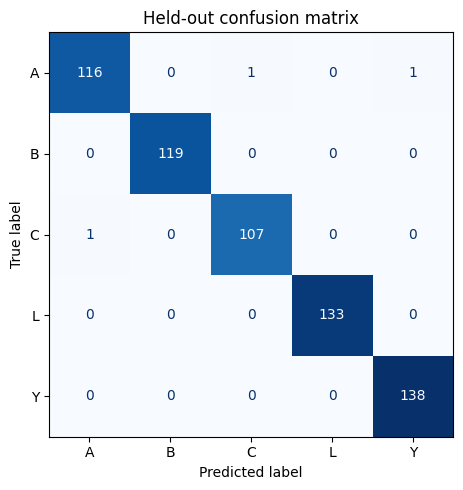

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_pred = model.predict(X_test)

print(f"Held-out accuracy: {accuracy_score(y_test, y_pred):.2%}")
print()
print(classification_report(
    y_test,
    y_pred,
    labels=list(CLASSES),
    digits=3,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=list(CLASSES),
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax,
)
ax.set_title("Held-out confusion matrix")
plt.tight_layout()
plt.show()


In [7]:
import joblib
from google.colab import files

model_path = "/content/asl_random_forest_abcly.joblib"

joblib.dump(model, model_path, compress=3)

loaded_model = joblib.load(model_path)
np.testing.assert_array_equal(loaded_model.predict(X_test), y_pred)

print(f"Saved and verified: {model_path}")
files.download(model_path)

Saved and verified: /content/asl_random_forest_abcly.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from string import ascii_uppercase

EXPANDED_CLASSES = tuple(letter for letter in ascii_uppercase if letter not in "JZ")
expanded_image_paths = {}

for letter in EXPANDED_CLASSES:
    folder = train_dir / letter
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing class folder: {folder}")

    paths = sorted(
        path
        for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    if not paths:
        raise FileNotFoundError(f"No images found in {folder}")

    expanded_image_paths[letter] = paths
    print(f"{letter}: {len(paths):,} images")

print(f"\nClasses: {len(EXPANDED_CLASSES)}")
print(f"Total images available: {sum(map(len, expanded_image_paths.values())):,}")

A: 3,000 images
B: 3,000 images
C: 3,000 images
D: 3,000 images
E: 3,000 images
F: 3,000 images
G: 3,000 images
H: 3,000 images
I: 3,000 images
K: 3,000 images
L: 3,000 images
M: 3,000 images
N: 3,000 images
O: 3,000 images
P: 3,000 images
Q: 3,000 images
R: 3,000 images
S: 3,000 images
T: 3,000 images
U: 3,000 images
V: 3,000 images
W: 3,000 images
X: 3,000 images
Y: 3,000 images

Classes: 24
Total images available: 72,000


In [9]:
EXPANDED_IMAGES_PER_CLASS = 300
checkpoint_dir = Path(
    f"/content/asl_static24_landmarks_v1_{EXPANDED_IMAGES_PER_CLASS}_seed{SEED}"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

feature_batches = []
label_batches = []

with vision.HandLandmarker.create_from_options(options) as detector:
    for letter in EXPANDED_CLASSES:
        checkpoint = checkpoint_dir / f"{letter}.npy"
        paths = expanded_image_paths[letter]
        sample_size = min(EXPANDED_IMAGES_PER_CLASS, len(paths))

        if checkpoint.is_file():
            letter_features = np.load(checkpoint, allow_pickle=False)
            print(f"{letter}: {len(letter_features)}/{sample_size} usable (loaded)")
        else:
            rng = np.random.default_rng(SEED + ord(letter))
            indices = rng.choice(len(paths), size=sample_size, replace=False)
            vectors = []

            for index in tqdm(indices, desc=f"Letter {letter}", unit="image"):
                bgr = cv2.imread(str(paths[index]))
                if bgr is None:
                    continue

                height, width = bgr.shape[:2]
                rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
                result = detector.detect(image)

                if result.hand_landmarks:
                    vector = normalize_landmarks(
                        result.hand_landmarks[0], width, height
                    )
                    if vector is not None:
                        vectors.append(vector)

            letter_features = np.asarray(vectors, dtype=np.float32).reshape(-1, 63)

            temp_path = checkpoint.with_suffix(".tmp.npy")
            np.save(temp_path, letter_features, allow_pickle=False)
            temp_path.replace(checkpoint)
            print(f"{letter}: {len(letter_features)}/{sample_size} usable (saved)")

        feature_batches.append(letter_features)
        label_batches.append(np.repeat(letter, len(letter_features)))

X_expanded = np.concatenate(feature_batches, axis=0)
y_expanded = np.concatenate(label_batches)

print(f"\nExpanded feature matrix: {X_expanded.shape}")
print(f"Expanded labels: {y_expanded.shape}")
print(f"Letters with usable landmarks: {len(np.unique(y_expanded))}")

Letter A:   0%|          | 0/300 [00:00<?, ?image/s]

A: 231/300 usable (saved)


Letter B:   0%|          | 0/300 [00:00<?, ?image/s]

B: 217/300 usable (saved)


Letter C:   0%|          | 0/300 [00:00<?, ?image/s]

C: 192/300 usable (saved)


... (38 outputs left out)

Letter X:   0%|          | 0/300 [00:00<?, ?image/s]

X: 224/300 usable (saved)


Letter Y:   0%|          | 0/300 [00:00<?, ?image/s]

Y: 257/300 usable (saved)

Expanded feature matrix: (5556, 63)
Expanded labels: (5556,)
Letters with usable landmarks: 24


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_exp_train, X_exp_test, y_exp_train, y_exp_test = train_test_split(
    X_expanded,
    y_expanded,
    test_size=0.20,
    stratify=y_expanded,
    random_state=SEED,
)

expanded_model = RandomForestClassifier(
    n_estimators=150,
    random_state=SEED,
    n_jobs=2,
)
expanded_model.fit(X_exp_train, y_exp_train)

print(f"Training images: {len(y_exp_train):,}")
print(f"Held-out images: {len(y_exp_test):,}")
print(f"Trained letters ({len(expanded_model.classes_)}): "
      f"{', '.join(expanded_model.classes_)}")

Training images: 4,444
Held-out images: 1,112
Trained letters (24): A, B, C, D, E, F, G, H, I, K, L, M, N, O, P, Q, R, S, T, U, V, W, X, Y


Held-out accuracy: 97.03%

              precision    recall  f1-score   support

           A      0.977     0.913     0.944        46
           B      1.000     1.000     1.000        43
           C      1.000     0.974     0.987        38
           D      0.980     0.960     0.970        50
           E      0.978     1.000     0.989        45
           F      1.000     1.000     1.000        57
           G      1.000     1.000     1.000        47
           H      1.000     0.958     0.979        48
           I      1.000     1.000     1.000        48
           K      0.963     0.963     0.963        54
           L      0.980     1.000     0.990        48
           M      0.789     0.938     0.857        32
           N      0.909     0.800     0.851        25
           O      0.938     0.957     0.947        47
           P      0.978     1.000     0.989        45
           Q      0.976     0.976     0.976        42
           R      0.923     0.980     0.950        49


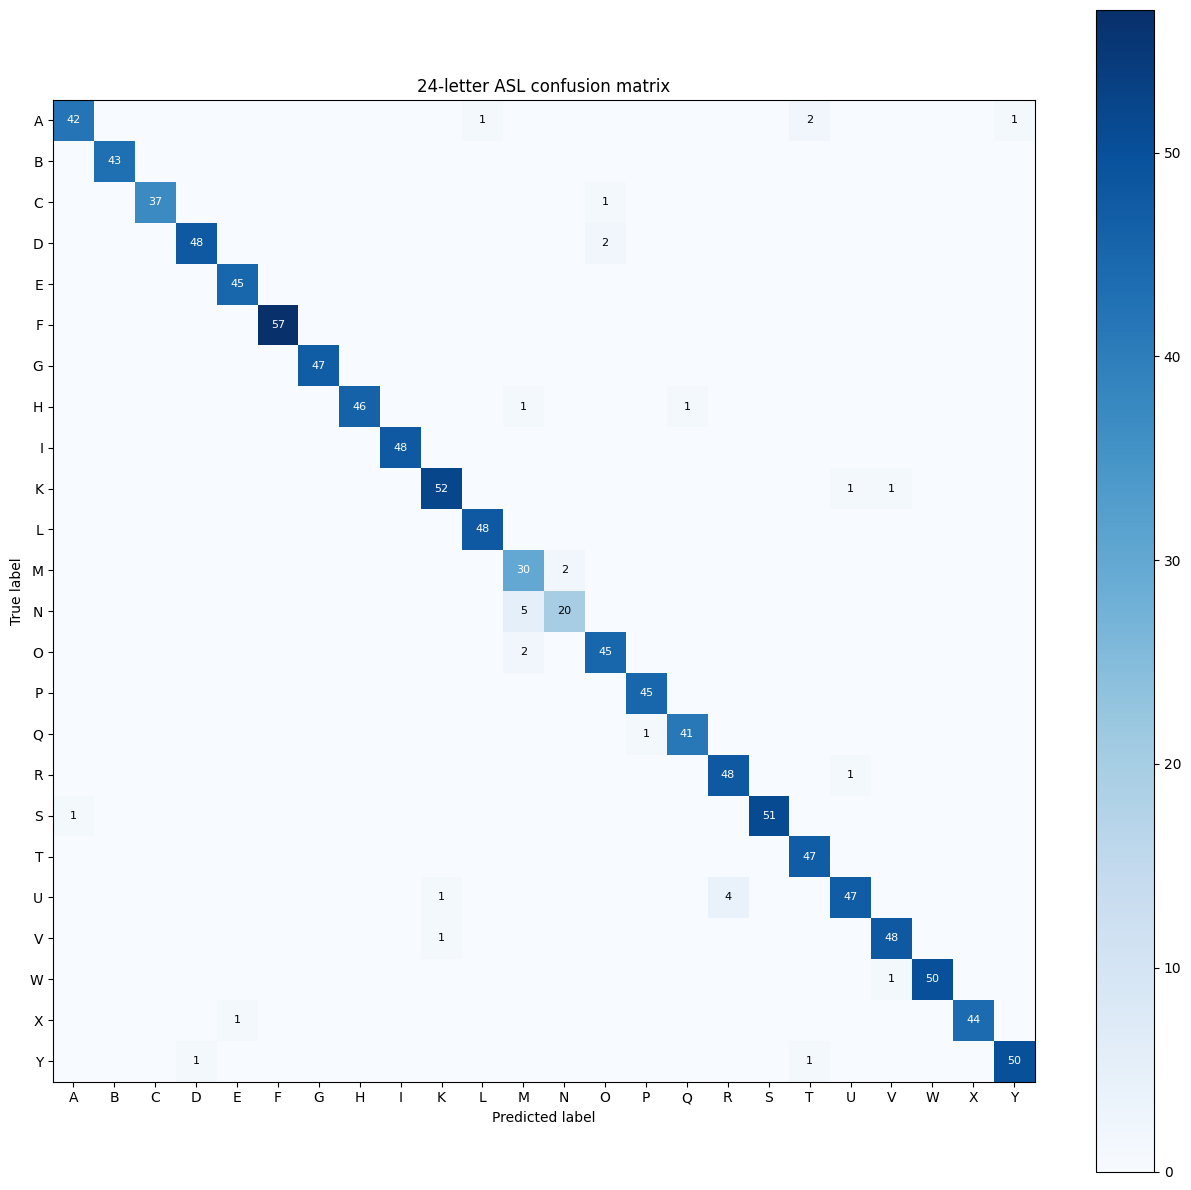

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)

y_exp_pred = expanded_model.predict(X_exp_test)

print(f"Held-out accuracy: {accuracy_score(y_exp_test, y_exp_pred):.2%}")
print()
print(
    classification_report(
        y_exp_test,
        y_exp_pred,
        labels=EXPANDED_CLASSES,
        digits=3,
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(13, 12))
display = ConfusionMatrixDisplay.from_predictions(
    y_exp_test,
    y_exp_pred,
    labels=EXPANDED_CLASSES,
    cmap="Blues",
    include_values=False,
    ax=ax,
)

# Show counts where at least one prediction fell in the cell.
matrix = display.confusion_matrix
for row, col in zip(*matrix.nonzero()):
    count = matrix[row, col]
    ax.text(
        col, row, str(count),
        ha="center", va="center", fontsize=8,
        color="white" if count > matrix.max() / 2 else "black",
    )

ax.set_title("24-letter ASL confusion matrix")
fig.tight_layout()
plt.show()

In [12]:
import joblib
from google.colab import files

expanded_model_path = "/content/asl_random_forest_static24.joblib"

joblib.dump(expanded_model, expanded_model_path, compress=3)

reloaded_expanded_model = joblib.load(expanded_model_path)
np.testing.assert_array_equal(
    reloaded_expanded_model.predict(X_exp_test),
    y_exp_pred,
)

print(f"Saved and verified: {expanded_model_path}")
files.download(expanded_model_path)

Saved and verified: /content/asl_random_forest_static24.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
JZ_CLASSES = ("J", "Z")
jz_feature_rows = []
jz_labels = []

with vision.HandLandmarker.create_from_options(options) as detector:
    for letter in JZ_CLASSES:
        folder = train_dir / letter
        paths = sorted(
            path
            for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
        )
        if not paths:
            raise FileNotFoundError(f"No images found in {folder}")

        sample_size = min(EXPANDED_IMAGES_PER_CLASS, len(paths))
        rng = np.random.default_rng(SEED + ord(letter))
        indices = rng.choice(len(paths), size=sample_size, replace=False)
        usable = 0

        for index in tqdm(indices, desc=f"Letter {letter}", unit="image"):
            bgr = cv2.imread(str(paths[index]))
            if bgr is None:
                continue

            height, width = bgr.shape[:2]
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            result = detector.detect(image)

            if not result.hand_landmarks:
                continue

            vector = normalize_landmarks(result.hand_landmarks[0], width, height)
            if vector is None:
                continue

            jz_feature_rows.append(vector)
            jz_labels.append(letter)
            usable += 1

        print(f"{letter}: {usable}/{sample_size} usable")

X_jz = np.asarray(jz_feature_rows, dtype=np.float32).reshape(-1, 63)
y_jz = np.asarray(jz_labels, dtype=str)

print(f"\nJ/Z feature matrix: {X_jz.shape}")

Letter J:   0%|          | 0/300 [00:00<?, ?image/s]

J: 256/300 usable


Letter Z:   0%|          | 0/300 [00:00<?, ?image/s]

Z: 228/300 usable

J/Z feature matrix: (484, 63)


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_jz_train, X_jz_test, y_jz_train, y_jz_test = train_test_split(
    X_jz,
    y_jz,
    test_size=0.20,
    stratify=y_jz,
    random_state=SEED,
)

X_az_train = np.concatenate((X_exp_train, X_jz_train), axis=0)
y_az_train = np.concatenate((y_exp_train, y_jz_train))

X_az_test = np.concatenate((X_exp_test, X_jz_test), axis=0)
y_az_test = np.concatenate((y_exp_test, y_jz_test))

az_model = RandomForestClassifier(
    n_estimators=150,
    random_state=SEED,
    n_jobs=2,
)
az_model.fit(X_az_train, y_az_train)

print(f"Training images: {len(y_az_train):,}")
print(f"Held-out images: {len(y_az_test):,}")
print(f"Trained letters ({len(az_model.classes_)}): {', '.join(az_model.classes_)}")

Training images: 4,831
Held-out images: 1,209
Trained letters (26): A, B, C, D, E, F, G, H, I, J, K, L, M, N, O, P, Q, R, S, T, U, V, W, X, Y, Z


Overall accuracy on 1,209 images: 96.86%
Accuracy on the same 24-letter holdout: 97.03% before, 96.67% after

J recall: 50/51 (98.04%)
  Predicted as I: 1

Z recall: 46/46 (100.00%)


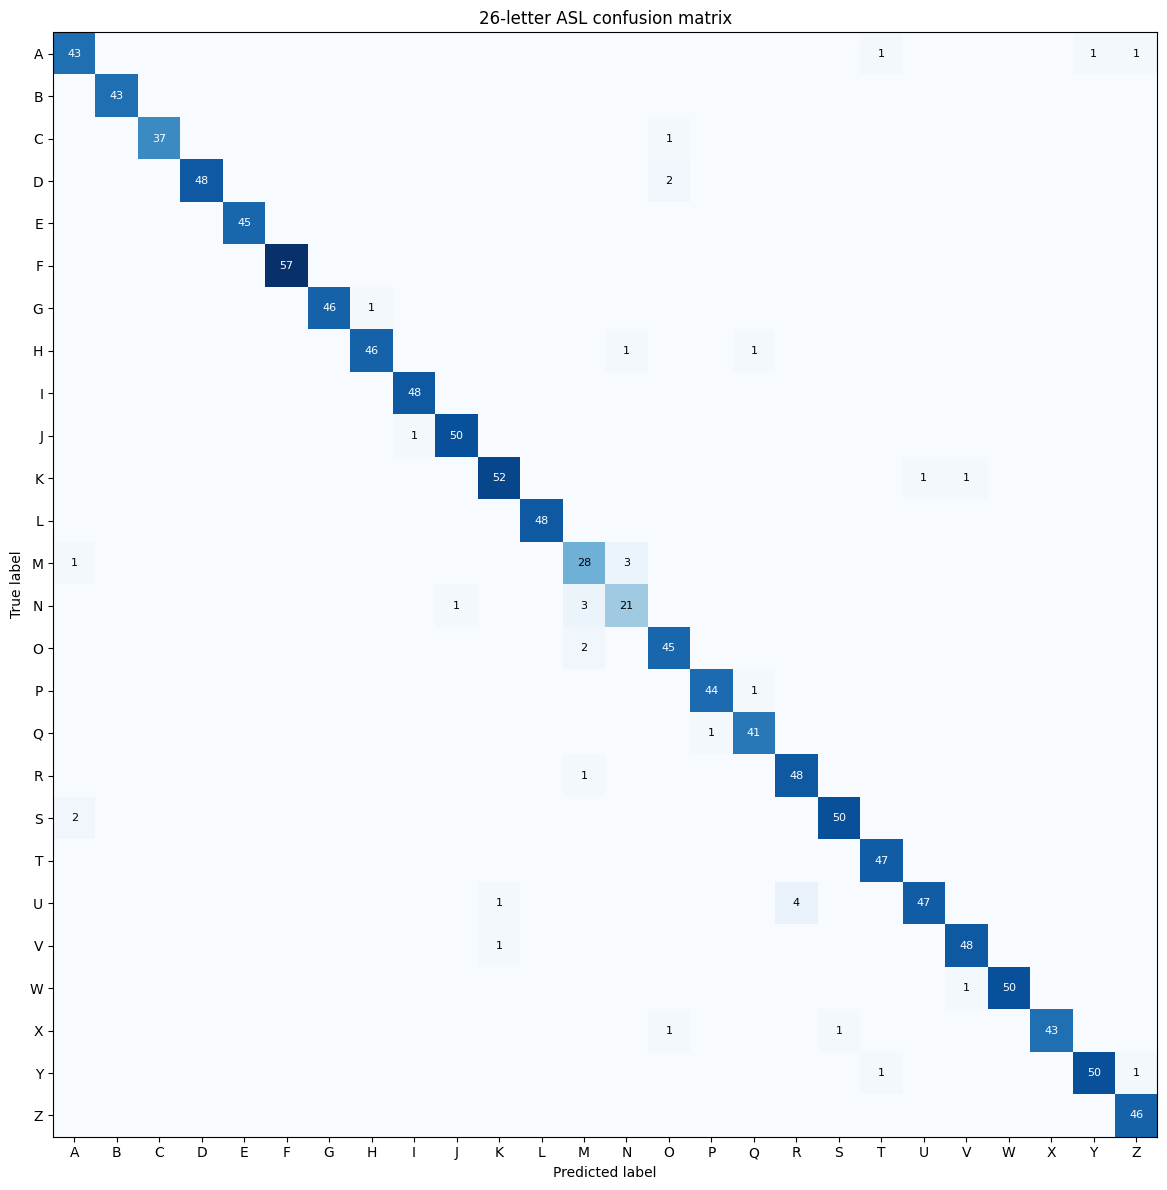

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
)

y_az_pred = az_model.predict(X_az_test)
az_classes = az_model.classes_
matrix = confusion_matrix(y_az_test, y_az_pred, labels=az_classes)

original_accuracy = accuracy_score(y_exp_test, y_exp_pred)
expanded_accuracy = accuracy_score(y_exp_test, az_model.predict(X_exp_test))

print(f"Overall accuracy on {len(y_az_test):,} images: "
      f"{accuracy_score(y_az_test, y_az_pred):.2%}")
print(f"Accuracy on the same 24-letter holdout: "
      f"{original_accuracy:.2%} before, {expanded_accuracy:.2%} after")

for letter in ("J", "Z"):
    row = int(np.flatnonzero(az_classes == letter)[0])
    correct = int(matrix[row, row])
    total = int(matrix[row].sum())
    print(f"\n{letter} recall: {correct}/{total} ({correct / total:.2%})")

    for predicted_letter, count in zip(az_classes, matrix[row]):
        if predicted_letter != letter and count:
            print(f"  Predicted as {predicted_letter}: {count}")

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(matrix, display_labels=az_classes).plot(
    ax=ax,
    cmap="Blues",
    include_values=False,
    colorbar=False,
)

for row, col in zip(*matrix.nonzero()):
    count = matrix[row, col]
    ax.text(
        col, row, str(count),
        ha="center", va="center", fontsize=8,
        color="white" if count > matrix.max() / 2 else "black",
    )

ax.set_title("26-letter ASL confusion matrix")
fig.tight_layout()
plt.show()

In [16]:
import joblib
import numpy as np
from google.colab import files

az_model_path = "/content/asl_random_forest_az_still_images.joblib"

joblib.dump(az_model, az_model_path, compress=3)

reloaded_az_model = joblib.load(az_model_path)
np.testing.assert_array_equal(
    reloaded_az_model.predict(X_az_test),
    y_az_pred,
)

print(f"Saved and verified: {az_model_path}")
files.download(az_model_path)

Saved and verified: /content/asl_random_forest_az_still_images.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from google.colab import files

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload exactly one photo.")

filename, image_bytes = next(iter(uploaded.items()))
bgr = cv2.imdecode(np.frombuffer(image_bytes, dtype=np.uint8), cv2.IMREAD_COLOR)

if bgr is None:
    raise ValueError(f"Could not open {filename}.")

height, width = bgr.shape[:2]
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

with vision.HandLandmarker.create_from_options(options) as detector:
    result = detector.detect(image)

if not result.hand_landmarks:
    print("No hand detected. Try a photo with the whole hand visible.")
else:
    vector = normalize_landmarks(result.hand_landmarks[0], width, height)
    if vector is None:
        print("Could not normalize the detected hand.")
    else:
        classifier = joblib.load(az_model_path)
        print(f"Predicted letter: {classifier.predict(vector.reshape(1, 63))[0]}")

Saving test_hand.png to test_hand.png
Predicted letter: L
